## Problem 7: Statement

The generation of equally distributed pseudo random numbers with so-called *Linear Congruential Generator* (LCG) proceeds according to the rule

$$ X_{i+1}= (aX_i +c)\ mod \ m $$

where for the following parts of this homework the (intentionally non-optimal) param3eters should be chosen as $a=5$, $c=0$, $m=2**11=2048$, $ X_0=1$.

(a) Implement an LCG with these parameters and choose an appropriatte normalisation such that $X_i \in [0,1)$.

(b) Plot the time series $X_i$ of $10^4$ sucessive random numbers and determine their period $\tau$. Which meaning has this quantity?

(c) Compute the average $\bar{X} =  \sum_{i=1}^N X_i/N$ and the estimator for the variance $\hat{\sigma}_X^2=\bar{X^2}-\bar{X}^2$ for $N = \tau , 10\tau, 100\tau$ random numbers. Why do the resulčts not improve isnpite the higher statistics?

(d) Plot the so-called running average $\bar{X} (n) =\sum_{i=1}^n X_i/n$ as function of n in the interval $n \in [30 000, 40 000]$.

(e) Plot an xy graph with $x= X_i$ and $y=X_{i+1}$ for $i=1,3,5,...$


## Problem 7: Solution

(a)

The linear congruential generator (LCG) generates a sequence of integers according to

$$
X_{i+1}=(aX_i+c) \bmod m \tag{1}
$$

with $a=5$, $c=0$, $m=2^{11}=2048$ and $X_0=1$. The remainder of a division by $m$ is always one of the integers $0,1,\dots,m-1$. Therefore, if we divide by $m$ we get numbers in the interval $[0,1)$:

$$
U_i=\frac{X_i}{m} \tag{2}
$$

We implement the generator and generate $10^5$ numbers, which is enough for all parts of this problem.

In [9]:
import numpy as np
from matplotlib import pyplot as plt

a = 5
c = 0
m = 2**11
X_0 = 1

def LCG(n):
    X = [X_0]
    for i in range(n):
        X.append((a*X[-1]+c) % m)
    return X

X = LCG(10**5)
U = np.array(X)/m

print("First 10 X_i:", X[:10])
print("First 10 U_i:", U[:10])


First 10 X_i: [1, 5, 25, 125, 625, 1077, 1289, 301, 1505, 1381]
First 10 U_i: [4.88281250e-04 2.44140625e-03 1.22070312e-02 6.10351562e-02
 3.05175781e-01 5.25878906e-01 6.29394531e-01 1.46972656e-01
 7.34863281e-01 6.74316406e-01]


(b)

Now we plot the time series of $10^4$ successive random numbers $U_i$.

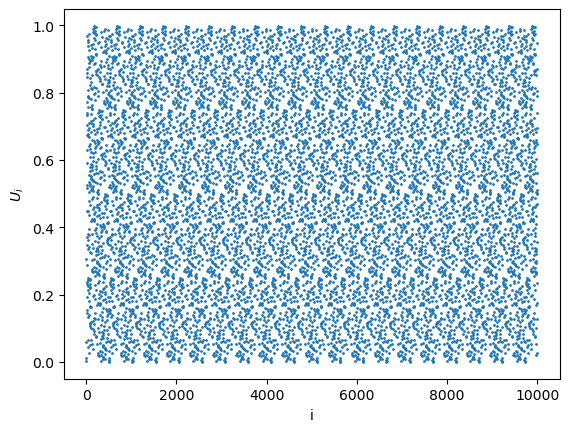

In [10]:
i = np.linspace(1, 10**4+1, 10**4)

plt.plot(i, U[1:10**4+1], ".", markersize=2)
plt.xlabel("i")
plt.ylabel(r"$U_i$")
plt.show()


Figure 1. Time series of $10^4$ successive random numbers $U_i$ of the LCG

The time series does not look random, we see a regular pattern that repeats itself. The period $\tau$ is the number of steps after which the generator returns to its starting value $X_0$. Since $X_{i+1}$ depends only on $X_i$, from then on the whole sequence repeats itself. We determine $\tau$ by running through the sequence until $X_0$ appears again.

In [11]:
tau = 1
while X[tau] != X_0:
    tau += 1

print("Period tau =", tau)


Period tau = 512


To see the period better, we plot only the first three periods and mark $i=\tau, 2\tau, 3\tau$.

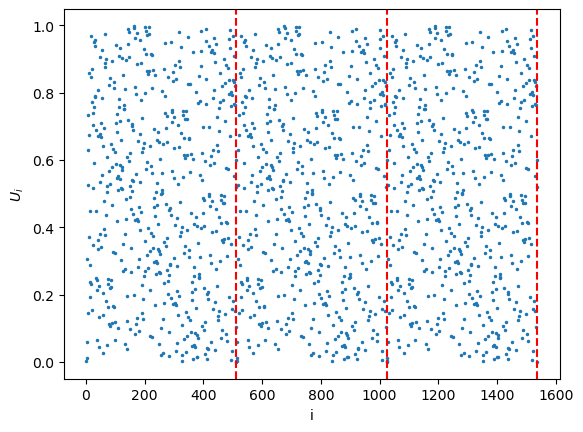

In [12]:
i = np.linspace(1, 3*tau+1, 3*tau)

plt.plot(i, U[1:3*tau+1], ".", markersize=3)
for k in [1, 2, 3]:
    plt.axvline(k*tau, linestyle="--", color="red")
plt.xlabel("i")
plt.ylabel(r"$U_i$")
plt.show()


Figure 2. First three periods of the time series. The red dashed lines are at $i=\tau, 2\tau, 3\tau$

So the period is $\tau=512$. 

The period tells us how many different random numbers the generator can produce before it repeats itself. 

(c)

Now we compute the average and the estimator for the variance

$$
\bar{X}=\frac{1}{N}\sum_{i=1}^{N}U_i, \qquad \hat{\sigma}_X^2=\overline{X^2}-\bar{X}^2 \tag{3}
$$

for $N=\tau, 10\tau, 100\tau$. For equally distributed numbers in $[0,1)$ the exact values are $1/2$ and $1/12$.

In [13]:
print("EXACT VALUES: mean =", 1/2, ", variance =", 1/12)

for N in [tau, 10*tau, 100*tau]:
    X_bar = np.mean(U[1:N+1])
    X2_bar = np.mean(U[1:N+1]**2)
    print(f"For N={N}: mean = {X_bar}, variance = {X2_bar - X_bar**2}")


EXACT VALUES: mean = 0.5 , variance = 0.08333333333333333
For N=512: mean = 0.49951171875, variance = 0.08333301544189453
For N=5120: mean = 0.49951171875, variance = 0.08333301544189453
For N=51200: mean = 0.49951171875, variance = 0.08333301544189453


The results are the same for all three values of $N$ (apart from rounding errors in the last digits). For independent random numbers the error of the average decreases with $1/\sqrt{N}$. Here, however, after $\tau$ numbers the same numbers come again. For $N=10\tau$ and $N=100\tau$ we just average $10$ and $100$ times over the same $512$ numbers, so we get exactly the same result as for $N=\tau$ and no new information.

The difference to $1/2$ and $1/12$ is not a statistical error but comes from the generator itself. One period contains the $512$ numbers $(1+4k)/2048$, $k=0,\dots,511$, and their average is

$$
\bar{X}_\tau=\frac{1023}{2048}=0.49951171875 \tag{4}
$$

which is exactly the value we found. This can only be improved by a generator with a much larger period.

(d)

The running average is

$$
\bar{X}(n)=\frac{1}{n}\sum_{i=1}^{n}U_i \tag{5}
$$

and we plot it for $n\in[30000,40000]$.

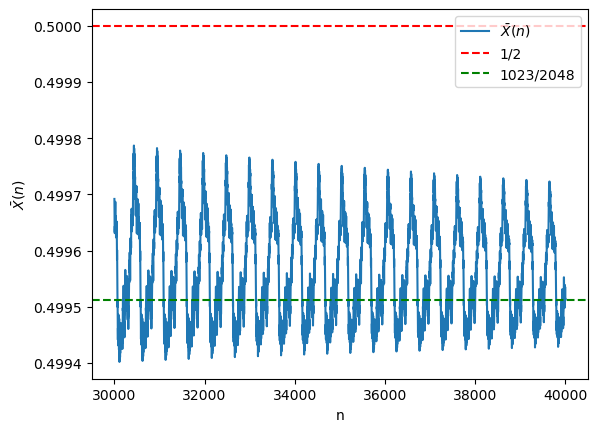

In [14]:
running_average = np.cumsum(U[1:])/np.arange(1, len(U))

n = np.arange(30000, 40001)

plt.plot(n, running_average[n-1], label=r"$\bar{X}(n)$")
plt.axhline(1/2, linestyle="--", color="red", label="1/2")
plt.axhline(1023/2048, linestyle="--", color="green", label="1023/2048")
plt.xlabel("n")
plt.ylabel(r"$\bar{X}(n)$")
plt.legend()
plt.show()


Figure 3. Running average $\bar{X}(n)$ for $n\in[30000,40000]$

(e)

Finally we plot $x=U_i$ against $y=U_{i+1}$ for $i=1,3,5,\dots$

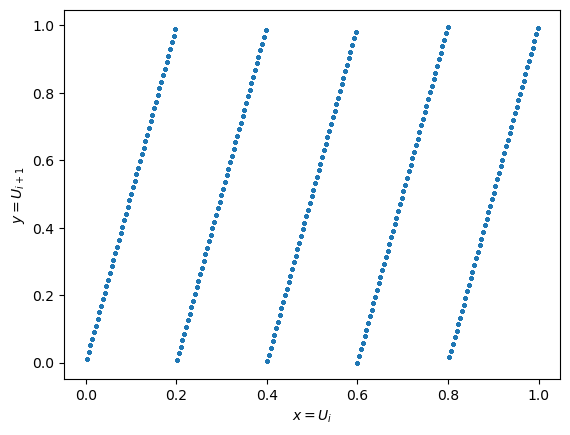

Number of points: 5000
Number of different points: 256


In [15]:
x = U[1:10**4:2]
y = U[2:10**4+1:2]

plt.plot(x, y, ".", markersize=4)
plt.xlabel(r"$x=U_i$")
plt.ylabel(r"$y=U_{i+1}$")
plt.show()

print("Number of points:", len(x))
print("Number of different points:", len(set(zip(x, y))))


Figure 4. $U_{i+1}$ against $U_i$ for $i=1,3,5,\dots,9999$

## Problem 8: Statement

Write a Monte Carlo computer program for the simulation of the 1D Ising model with $ N = 20, 100, 1000, 10000$ spins and free boundary conditions. Use for the spin updates the Metropolis algorithm.

Determine the mean energy, specific heat, magnetisation and susceptibility  for different temperatures in the inverse temperature range $\beta=J/(k_bT) =0,...,2.$ 

Check your results by comparison with the analytical results for the mean energy and specific heat of Problem 1 respectively for N=20 spins and *all* quantities by means of the exact enumerations of Problems 3 and 5. 

Measure also the acceptance rate of the spin-flip proposals.

## Problem 8: Solution

We simulate the 1D Ising model with free boundary conditions and $h=0$. As in Homework 1, the energy is

$$
E=-J\sum_{i=1}^{N-1}s_is_{i+1} \tag{7}
$$

and we set $J=k_B=1$, so that $\beta=1/T$.

In the Metropolis algorithm we choose a spin $i$ at random and calculate the energy change if this spin is flipped

$$
\Delta E=2Js_i(s_{i-1}+s_{i+1}) \tag{8}
$$

where for the first and the last spin the missing neighbour is left out (free boundary conditions). If $\Delta E\le0$ the flip is accepted, otherwise it is accepted with probability $e^{-\beta\Delta E}$. $N$ such steps are one sweep. We start from a random configuration, do $10^4$ sweeps without measuring to reach equilibrium, and then measure $E$ and $M=\sum_i s_i$ after every sweep.

From the measurements we calculate the per spin quantities

$$
e=\frac{\langle E\rangle}{N}, \qquad c=\frac{\beta^2}{N}\left(\langle E^2\rangle-\langle E\rangle^2\right) \tag{9}
$$

$$
m=\frac{\langle |M|\rangle}{N}, \qquad \chi=\frac{\beta}{N}\left(\langle M^2\rangle-\langle M\rangle^2\right)=\frac{\beta}{N}\langle M^2\rangle \tag{10}
$$

For $h=0$ we have $\langle M\rangle=0$ by symmetry, therefore we use $\langle |M|\rangle$ for the magnetisation. The acceptance rate is the number of accepted flips divided by the number of proposed flips.

In [16]:
import numpy as np
import math
import time
from numba import njit, prange
from matplotlib import pyplot as plt

J = 1.0
k_b = 1.0

@njit
def metropolis(N, beta, n_therm, n_sweeps, seed):
    np.random.seed(seed)

    # random start configuration
    s = np.ones(N)
    for i in range(N):
        if np.random.random() < 0.5:
            s[i] = -1

    E = 0.0
    for i in range(N-1):
        E += -J*s[i]*s[i+1]
    M = np.sum(s)

    E_sum = 0.0
    E2_sum = 0.0
    M_sum = 0.0
    M2_sum = 0.0
    accepted = 0

    for sweep in range(n_therm + n_sweeps):
        for step in range(N):
            i = np.random.randint(N)
            neighbours = 0.0
            if i > 0:
                neighbours += s[i-1]
            if i < N-1:
                neighbours += s[i+1]
            dE = 2*J*s[i]*neighbours
            if dE <= 0 or np.random.random() < np.exp(-beta*dE):
                s[i] = -s[i]
                E += dE
                M += 2*s[i]
                if sweep >= n_therm:
                    accepted += 1
        if sweep >= n_therm:
            E_sum += E
            E2_sum += E*E
            M_sum += abs(M)
            M2_sum += M*M

    return E_sum/n_sweeps, E2_sum/n_sweeps, M_sum/n_sweeps, M2_sum/n_sweeps, accepted/(N*n_sweeps)

@njit(parallel=True)
def simulate(N, betas, n_therm, n_sweeps):
    results = np.zeros((len(betas), 5))
    for k in prange(len(betas)):
        E, E2, M_abs, M2, acc = metropolis(N, betas[k], n_therm, n_sweeps, 1000*N + k)
        results[k, 0] = E
        results[k, 1] = E2
        results[k, 2] = M_abs
        results[k, 3] = M2
        results[k, 4] = acc
    return results


Now we run the simulation for $N=20,100,1000,10000$ and $\beta=0,0.1,\dots,2$.

In [17]:
betas = np.linspace(0, 2, 21)
N_values = [20, 100, 1000, 10000]

n_therm = 10**4
n_sweeps = {20: 400000, 100: 400000, 1000: 200000, 10000: 100000}

e_MC = {}
c_MC = {}
m_MC = {}
chi_MC = {}
acc_MC = {}

print("MONTE CARLO SIMULATION:")
for N in N_values:
    t_start = time.time()
    results = simulate(N, betas, n_therm, n_sweeps[N])
    E, E2, M_abs, M2, acc = results[:, 0], results[:, 1], results[:, 2], results[:, 3], results[:, 4]

    e_MC[N] = E/N
    c_MC[N] = betas**2*(E2 - E**2)/N
    m_MC[N] = M_abs/N
    chi_MC[N] = betas*M2/N
    acc_MC[N] = acc
    print(f"For N={N}: done in {time.time() - t_start:.1f} s")


MONTE CARLO SIMULATION:


OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


For N=20: done in 2.1 s
For N=100: done in 1.3 s
For N=1000: done in 6.0 s
For N=10000: done in 38.1 s


From Problem 1 (Homework 1) we know the exact mean energy and specific heat of the free chain. Per spin they are

$$
e=-J\frac{N-1}{N}\tanh(\beta J), \qquad c=(\beta J)^2\frac{N-1}{N}\operatorname{sech}^2(\beta J) \tag{11}
$$

For $N=20$ we determine the density of states $\Omega(E,M)$ by exact enumeration as in Problems 3 and 5 and calculate all quantities from it.

In [18]:
def e_analytic(N, beta):
    return -J*(N-1)/N*np.tanh(J*beta)

def c_analytic(N, beta):
    return (J*beta)**2*(N-1)/N/np.cosh(J*beta)**2


In [19]:
def exp(x):
    return math.exp(x)

spins=[-1,1]

distr={}
for s1 in spins:
    for s2 in spins:
        for s3 in spins:
            for s4 in spins:
                for s5 in spins:
                    for s6 in spins:
                        for s7 in spins:
                            for s8 in spins:
                                for s9 in spins:
                                    for s10 in spins:
                                        for s11 in spins:
                                            for s12 in spins:
                                                for s13 in spins:
                                                    for s14 in spins:
                                                        for s15 in spins:
                                                            for s16 in spins:
                                                                for s17 in spins:
                                                                    for s18 in spins:
                                                                        for s19 in spins:
                                                                            for s20 in spins:
                                                                                E_20=-J*(s1*s2+s2*s3+s3*s4+s4*s5+s5*s6+s6*s7+s7*s8+s8*s9+s9*s10+s10*s11+s11*s12+s12*s13+s13*s14+s14*s15+s15*s16+s16*s17+s17*s18+s18*s19+s19*s20)
                                                                                M_20=(s1+s2+s3+s4+s5+s6+s7+s8+s9+s10+s11+s12+s13+s14+s15+s16+s17+s18+s19+s20)

                                                                                if (E_20, M_20) in distr:
                                                                                    distr[(E_20, M_20)]+=1
                                                                                else:
                                                                                    distr.update({(E_20, M_20) : 1})

print("SUM_E,M OMEGA(E,M) =", sum(distr.values()))
if sum(distr.values()) == 1048576:
    print("-> check passed")


SUM_E,M OMEGA(E,M) = 1048576
-> check passed


With $\Omega(E,M)$ the exact values for $N=20$ are, as in eq. (8) and (9) of Homework 3,

$$
\langle A\rangle=\frac{\sum_{E,M}A\,\Omega(E,M)e^{-\beta E}}{\sum_{E,M}\Omega(E,M)e^{-\beta E}} \tag{12}
$$

for $A=E, E^2, |M|, M^2$.

In [20]:
def exact_enumeration(beta):
    N = 20
    Z = 0
    E_1 = 0
    E_2 = 0
    M_abs = 0
    M_2 = 0

    for E, M in distr:
        w = distr[E, M]*exp(-beta*E)
        Z += w
        E_1 += E*w
        E_2 += E*E*w
        M_abs += abs(M)*w
        M_2 += M*M*w

    E_1, E_2, M_abs, M_2 = E_1/Z, E_2/Z, M_abs/Z, M_2/Z
    return E_1/N, beta**2*(E_2 - E_1**2)/N, M_abs/N, beta*M_2/N

e_enum = np.array([exact_enumeration(beta)[0] for beta in betas])
c_enum = np.array([exact_enumeration(beta)[1] for beta in betas])
m_enum = np.array([exact_enumeration(beta)[2] for beta in betas])
chi_enum = np.array([exact_enumeration(beta)[3] for beta in betas])


Comparison for $N=20$. First we compare the numbers at a few values of $\beta$.

In [21]:
print("COMPARISON FOR N=20 (Monte Carlo / exact enumeration / analytical):")
for k in [5, 10, 15, 20]:
    beta = betas[k]
    print(f"beta={beta:.1f}:")
    print(f"   e   = {e_MC[20][k]:.4f} / {e_enum[k]:.4f} / {e_analytic(20, beta):.4f}")
    print(f"   c   = {c_MC[20][k]:.4f} / {c_enum[k]:.4f} / {c_analytic(20, beta):.4f}")
    print(f"   m   = {m_MC[20][k]:.4f} / {m_enum[k]:.4f}")
    print(f"   chi = {chi_MC[20][k]:.4f} / {chi_enum[k]:.4f}")


COMPARISON FOR N=20 (Monte Carlo / exact enumeration / analytical):
beta=0.5:
   e   = -0.4392 / -0.4390 / -0.4390
   c   = 0.1872 / 0.1868 / 0.1868
   m   = 0.2878 / 0.2884
   chi = 1.2747 / 1.2793
beta=1.0:
   e   = -0.7224 / -0.7235 / -0.7235
   c   = 0.3974 / 0.3990 / 0.3990
   m   = 0.4574 / 0.4601
   chi = 5.9914 / 6.0549
beta=1.5:
   e   = -0.8594 / -0.8599 / -0.8599
   c   = 0.3858 / 0.3863 / 0.3863
   m   = 0.6726 / 0.6745
   chi = 17.0112 / 17.0937
beta=2.0:
   e   = -0.9149 / -0.9158 / -0.9158
   c   = 0.2748 / 0.2685 / 0.2685
   m   = 0.8412 / 0.8459
   chi = 31.5732 / 31.8077


Then we plot the Monte Carlo results (points) together with the exact results (lines) for all $\beta$.

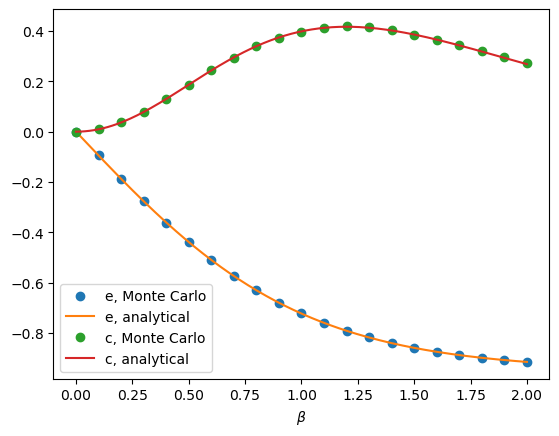

In [22]:
beta_fine = np.linspace(0, 2, 200)

plt.plot(betas, e_MC[20], "o", label="e, Monte Carlo")
plt.plot(beta_fine, e_analytic(20, beta_fine), label="e, analytical")
plt.plot(betas, c_MC[20], "o", label="c, Monte Carlo")
plt.plot(beta_fine, c_analytic(20, beta_fine), label="c, analytical")
plt.xlabel(r"$\beta$")
plt.legend()
plt.show()


Figure 5. Mean energy $e$ and specific heat $c$ per spin as a function of $\beta$ for $N=20$, Monte Carlo and analytical result of Problem 1

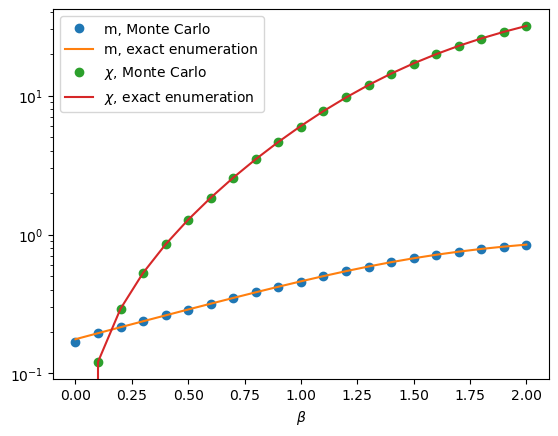

In [23]:
plt.plot(betas, m_MC[20], "o", label="m, Monte Carlo")
plt.plot(betas, m_enum, label="m, exact enumeration")
plt.plot(betas, chi_MC[20], "o", label=r"$\chi$, Monte Carlo")
plt.plot(betas, chi_enum, label=r"$\chi$, exact enumeration")
plt.yscale("log")
plt.xlabel(r"$\beta$")
plt.legend()
plt.show()


Figure 6. Magnetisation $m$ and susceptibility $\chi$ per spin as a function of $\beta$ for $N=20$, Monte Carlo and exact enumeration (logarithmic y-scale)

As we can see on Fig. 5 and Fig. 6, the Monte Carlo results for $N=20$ agree with the exact enumeration and the analytical results within about $1\%$.

The only exception is the magnetisation at $\beta=0$. There every flip is accepted, so one sweep is exactly $N=20$ flips and $M$ changes only by multiples of $4$ between measurements. The simulation therefore visits only half of the configurations.

Now we plot the results for all $N$. For $e$ and $c$ we also plot the analytical result eq. (11) as lines.

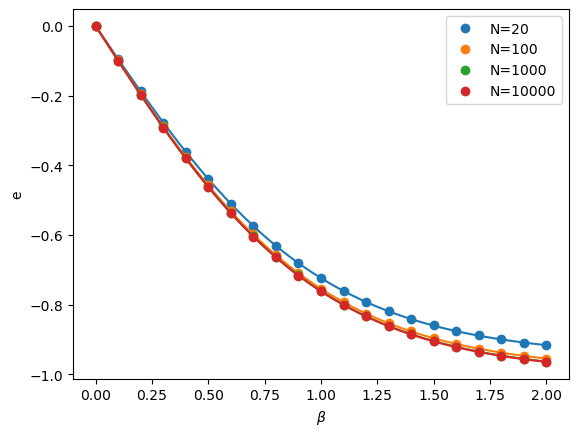

In [24]:
colors = ["C0", "C1", "C2", "C3"]

for N, col in zip(N_values, colors):
    plt.plot(betas, e_MC[N], "o", color=col, label=f"N={N}")
    plt.plot(beta_fine, e_analytic(N, beta_fine), color=col)
plt.xlabel(r"$\beta$")
plt.ylabel("e")
plt.legend()
plt.show()


Figure 7. Mean energy per spin $e$ as a function of $\beta$ for $N=20,100,1000,10000$. Points: Monte Carlo, lines: analytical result

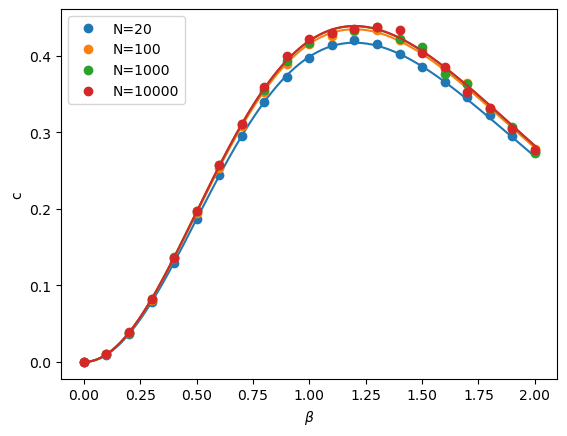

In [25]:
for N, col in zip(N_values, colors):
    plt.plot(betas, c_MC[N], "o", color=col, label=f"N={N}")
    plt.plot(beta_fine, c_analytic(N, beta_fine), color=col)
plt.xlabel(r"$\beta$")
plt.ylabel("c")
plt.legend()
plt.show()


Figure 8. Specific heat per spin $c$ as a function of $\beta$ for $N=20,100,1000,10000$. Points: Monte Carlo, lines: analytical result

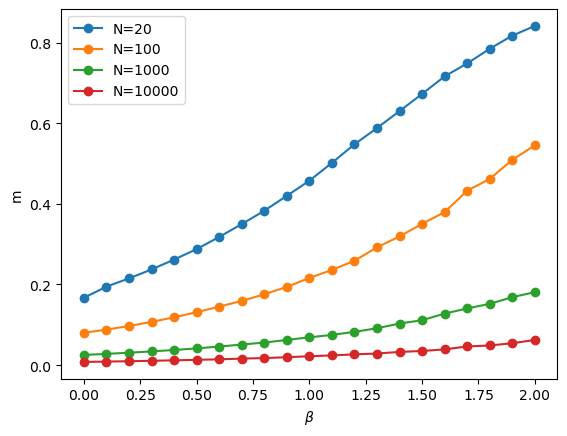

In [26]:
for N in N_values:
    plt.plot(betas, m_MC[N], "o-", label=f"N={N}")
plt.xlabel(r"$\beta$")
plt.ylabel("m")
plt.legend()
plt.show()


Figure 9. Magnetisation per spin $m=\langle|M|\rangle/N$ as a function of $\beta$ for $N=20,100,1000,10000$

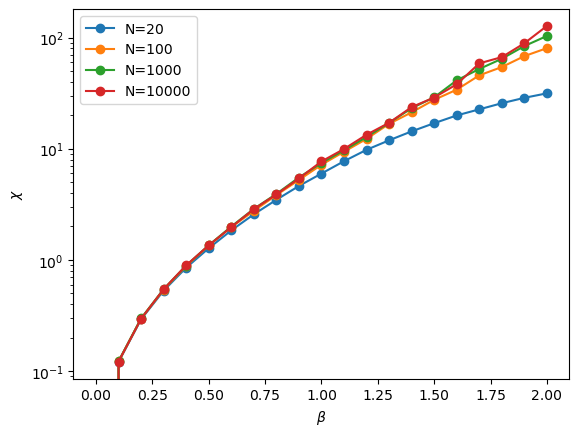

In [27]:
for N in N_values:
    plt.plot(betas, chi_MC[N], "o-", label=f"N={N}")
plt.yscale("log")
plt.xlabel(r"$\beta$")
plt.ylabel(r"$\chi$")
plt.legend()
plt.show()


Figure 10. Susceptibility per spin $\chi$ as a function of $\beta$ for $N=20,100,1000,10000$ (logarithmic y-scale)

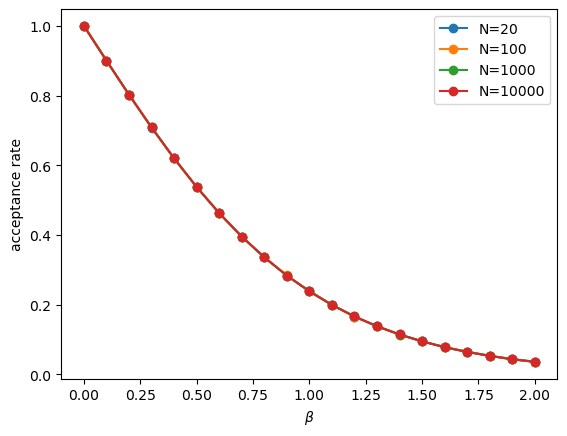

In [28]:
for N in N_values:
    plt.plot(betas, acc_MC[N], "o-", label=f"N={N}")
plt.xlabel(r"$\beta$")
plt.ylabel("acceptance rate")
plt.legend()
plt.show()


Figure 11. Acceptance rate of the spin flips as a function of $\beta$ for $N=20,100,1000,10000$